# Sismicidad de Colombia con el catálogo del USGS

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/teoria-riesgos/blob/main/book/03_amenazas/317_sismicidad_colombia.ipynb)

Este cuaderno **descarga datos reales** y muestra cómo caracterizar la sismicidad de una región: tasa de ocurrencia, distribución de profundidades y de magnitudes (relación de Gutenberg-Richter). Son los insumos del análisis probabilista de amenaza sísmica de [](301_sismo.md). Se puede ejecutar completo en Colab o en un computador, sin cuenta ni claves.

**Origen y licencia.** Adaptado del cuaderno «Análisis de Sismicidad de Colombia», de la Subdirección para el Conocimiento del Riesgo de la UNGRD ([cuadernos-reproducibles-crc004](https://scr-ungrd.github.io/cuadernos-reproducibles-crc004/), CC BY 4.0). Aquí se recortó el material interactivo (mapas y animación), se añadió la estimación de la magnitud de completitud y de la *b* por máxima verosimilitud, y se dejó el análisis estático.

**Datos.** Servicio web FDSN de eventos del USGS ([earthquake.usgs.gov/fdsnws/event/1](https://earthquake.usgs.gov/fdsnws/event/1/)), dominio público. Periodo 2000–2024, región entre 5° S y 13° N y entre 82° O y 65° O, magnitud mínima 3,0. La caja incluye parte de Ecuador, Perú, Venezuela y Panamá, por lo que **los sismos mayores del listado no son todos colombianos** (se muestra el lugar de cada uno).

```{warning}
Es un catálogo **global** del USGS, no el catálogo oficial del Servicio Geológico Colombiano (SGC), que tiene más estaciones locales y menor magnitud de completitud. Sirve para aprender el método; para un estudio de amenaza se debe usar el catálogo del SGC.
```

In [1]:
from io import StringIO
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy import stats

# ----------------------------- parámetros -----------------------------
PARAMS = dict(format="csv", starttime="2000-01-01", endtime="2024-12-31",
              minlatitude=-5, maxlatitude=13, minlongitude=-82, maxlongitude=-65,
              minmagnitude=3.0, orderby="time")
URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
AZUL, ROJO, NARANJA = "#0154a5", "#c0392b", "#e08e0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Descarga y limpieza

La consulta devuelve un CSV. Nos quedamos con tiempo, posición, profundidad y magnitud, y clasificamos cada sismo por profundidad focal: superficial (hasta 70 km), intermedio (70 a 300 km) y profundo (más de 300 km).

In [2]:
r = requests.get(URL, params=PARAMS, timeout=120); r.raise_for_status()
raw = pd.read_csv(StringIO(r.text))
df = raw[["time", "latitude", "longitude", "depth", "mag", "magType", "place"]].dropna(subset=["mag", "depth"]).copy()
df.columns = ["tiempo", "lat", "lon", "prof_km", "mag", "tipo_mag", "lugar"]
df["tiempo"] = pd.to_datetime(df["tiempo"], utc=True)
df["anio"] = df["tiempo"].dt.year
df["clase"] = pd.cut(df["prof_km"], [-10, 70, 300, 1000], labels=["Superficial (≤ 70 km)", "Intermedio (70–300 km)", "Profundo (> 300 km)"])
print(f"Eventos descargados: {len(raw):,}; válidos: {len(df):,}")
print(df["clase"].value_counts().to_string())
print("\nTipos de magnitud:", df["tipo_mag"].value_counts().head(4).to_dict())

Eventos descargados: 4,201; válidos: 4,201
clase
Superficial (≤ 70 km)     2290
Intermedio (70–300 km)    1910
Profundo (> 300 km)          1

Tipos de magnitud: {'mb': 3550, 'mww': 171, 'mwc': 139, 'mwr': 138}


## 2. Distribución en el tiempo

Un catálogo cambia con la red de estaciones: más estaciones detectan más sismos pequeños. Por eso la tasa anual **no** se interpreta como cambio de la actividad sin revisar la completitud.

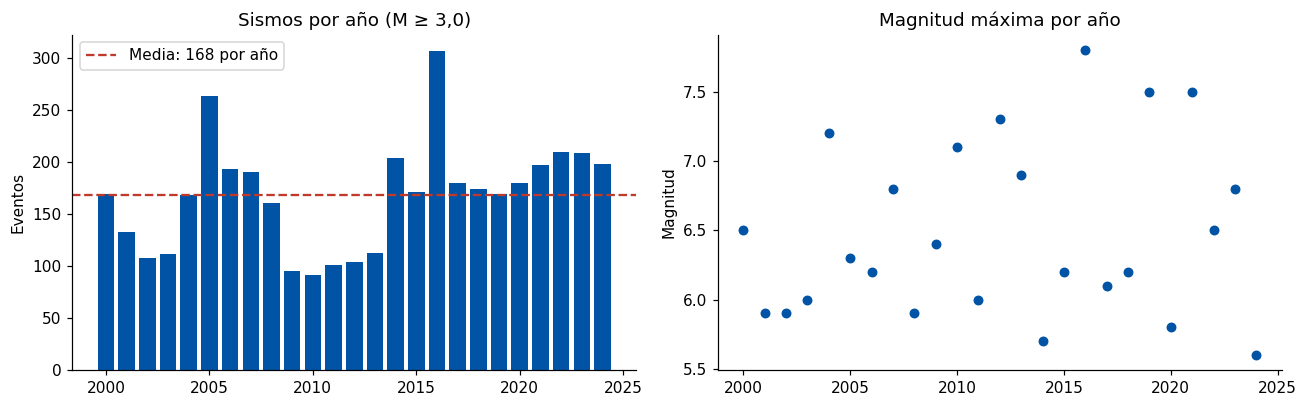

In [3]:
anual = df.groupby("anio").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(anual.index, anual.values, color=AZUL)
ax[0].axhline(anual.mean(), color=ROJO, ls="--", label=f"Media: {anual.mean():.0f} por año")
ax[0].set(title="Sismos por año (M ≥ 3,0)", ylabel="Eventos"); ax[0].legend()
mmax = df.groupby("anio")["mag"].max()
ax[1].scatter(mmax.index, mmax.values, c=AZUL, s=30)
ax[1].set(title="Magnitud máxima por año", ylabel="Magnitud")
plt.tight_layout(); plt.show()

## 3. Relación de Gutenberg-Richter

La relación $\log_{10} N = a - b\,M$ da el número $N$ de sismos de magnitud mayor o igual a $M$. El parámetro $b$ (cerca de 1 en muchas regiones) mide la proporción de sismos pequeños y grandes, y $a$ el nivel de actividad. Ambos alimentan el análisis probabilista de amenaza.

El ajuste debe usar solo magnitudes por encima de la **magnitud de completitud** $M_c$, la menor magnitud desde la cual el catálogo registra todos los eventos. La estimamos con el método del máximo de la curvatura (el bin con más eventos) y calculamos $b$ de dos formas: regresión sobre la curva acumulada y máxima verosimilitud (Aki, 1965; Utsu, 1966), que es la más usada.

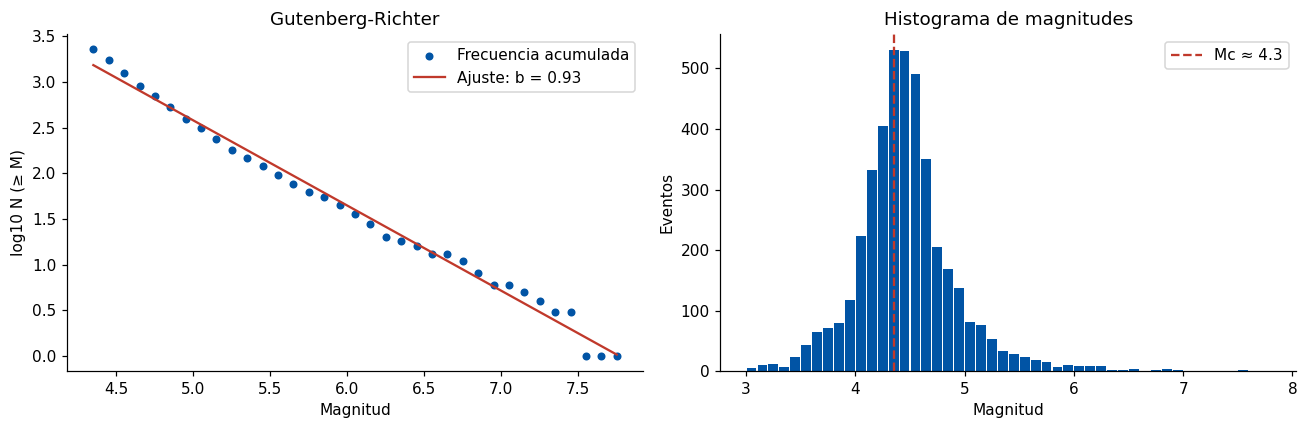

Magnitud de completitud (curvatura): Mc = 4.3  (n = 2,275 eventos por encima)
b por máxima verosimilitud: 1.06 ± 0.02
b por regresión acumulada:  0.93  (R² = 0.991)


In [4]:
def gr(mags, bin_=0.1):
    bins = np.round(np.arange(mags.min(), mags.max() + bin_, bin_), 2)
    h, edges = np.histogram(mags, bins=bins)
    centros = edges[:-1] + bin_ / 2
    mc = centros[np.argmax(h)]                       # máximo de curvatura
    sel = mags[mags >= mc]
    b_ml = np.log10(np.e) / (sel.mean() - (mc - bin_ / 2))   # Aki-Utsu
    b_se = b_ml / np.sqrt(len(sel))
    acum = np.array([(sel >= m).sum() for m in centros[centros >= mc]])
    m_ac = centros[centros >= mc]
    ok = acum > 0
    sl, ic, rr, _, _ = stats.linregress(m_ac[ok], np.log10(acum[ok]))
    return dict(mc=mc, n=len(sel), b_ml=b_ml, b_se=b_se, b_ls=-sl, a_ls=ic, r2=rr**2, m=m_ac[ok], logn=np.log10(acum[ok]), centros=centros, h=h)

g = gr(df["mag"].values)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(g["m"], g["logn"], s=18, c=AZUL, label="Frecuencia acumulada")
ax[0].plot(g["m"], g["a_ls"] - g["b_ls"] * g["m"], c=ROJO, label=f"Ajuste: b = {g['b_ls']:.2f}")
ax[0].set(xlabel="Magnitud", ylabel="log10 N (≥ M)", title="Gutenberg-Richter"); ax[0].legend()
ax[1].bar(g["centros"], g["h"], width=0.09, color=AZUL)
ax[1].axvline(g["mc"], c=ROJO, ls="--", label=f"Mc ≈ {g['mc']:.1f}")
ax[1].set(xlabel="Magnitud", ylabel="Eventos", title="Histograma de magnitudes"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Magnitud de completitud (curvatura): Mc = {g['mc']:.1f}  (n = {g['n']:,} eventos por encima)")
print(f"b por máxima verosimilitud: {g['b_ml']:.2f} ± {g['b_se']:.2f}")
print(f"b por regresión acumulada:  {g['b_ls']:.2f}  (R² = {g['r2']:.3f})")

Si $M_c$ es mayor que 3,0, los sismos entre 3,0 y $M_c$ **no** forman parte del ajuste: incluirlos subestima $b$. La regresión sobre la curva acumulada no es independiente entre puntos y suele sesgar el resultado, por eso se prefiere la máxima verosimilitud.

## 4. Profundidad focal

La profundidad y el tipo de fuente (subducción, intraplaca, cortical) cambian la atenuación del movimiento del suelo y el daño. En Colombia conviven sismos corticales, de subducción y de la zona profunda del Nido de Bucaramanga.

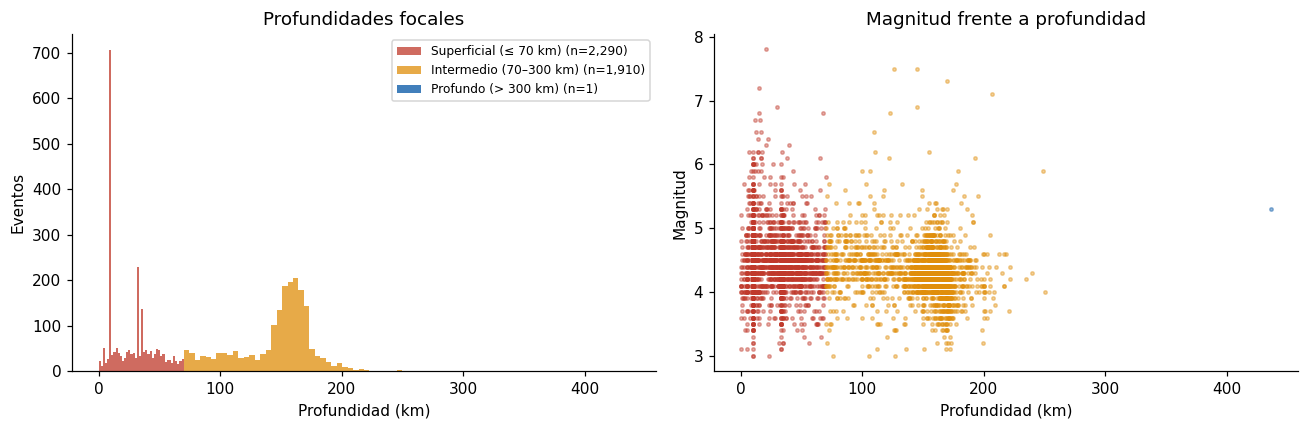

In [5]:
colores = {"Superficial (≤ 70 km)": ROJO, "Intermedio (70–300 km)": NARANJA, "Profundo (> 300 km)": AZUL}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, c in colores.items():
    s = df[df["clase"] == k]
    ax[0].hist(s["prof_km"], bins=40, color=c, alpha=.75, label=f"{k} (n={len(s):,})")
    ax[1].scatter(s["prof_km"], s["mag"], s=5, color=c, alpha=.4)
ax[0].set(xlabel="Profundidad (km)", ylabel="Eventos", title="Profundidades focales"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="Profundidad (km)", ylabel="Magnitud", title="Magnitud frente a profundidad")
plt.tight_layout(); plt.show()

## 5. Distribución espacial y sismos mayores

Mapa estático de epicentros con magnitud mayor o igual a 4,0 (tamaño por magnitud, color por profundidad) y los diez sismos de mayor magnitud del periodo.

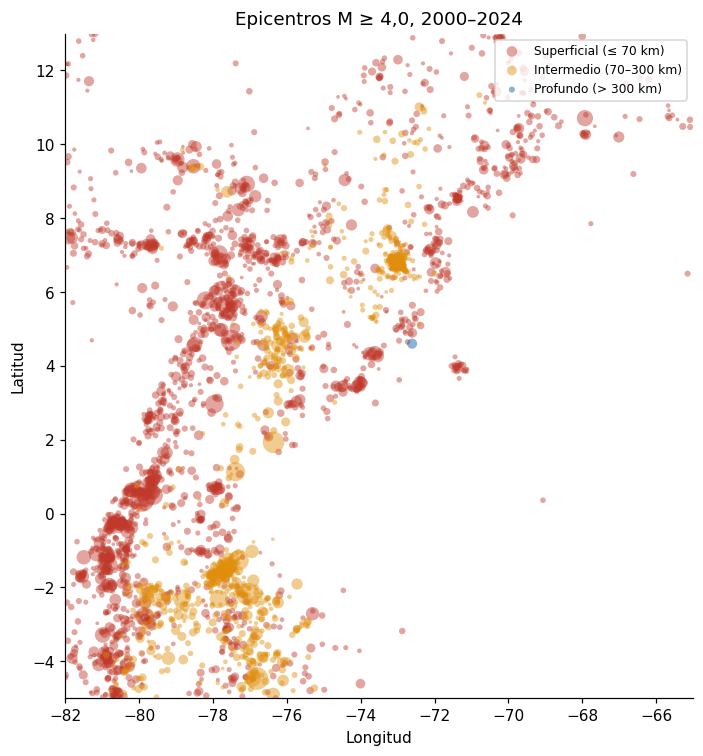

,Fecha,Mag.,Prof. (km),Lat,Lon,Lugar
0,2016-04-16,7.8,21.0,0.3819,-79.9218,"27 km SSE of Muisne, Ecuador"
1,2021-11-28,7.5,126.0,-4.4667,-76.8126,"43 km NNW of Barranca, Peru"
2,2019-02-22,7.5,145.0,-2.1862,-77.0505,"115 km ESE of Palora, Ecuador"
3,2012-09-30,7.3,170.0,1.9290,-76.3620,"11 km WNW of San Agustín, Colombia"
4,2004-11-15,7.2,15.0,4.6950,-77.5080,"32 km SSW of Pizarro, Colombia"
5,2010-08-12,7.1,207.0,-1.2660,-77.3060,Ecuador
6,2016-05-18,6.9,30.0,0.4947,-79.6160,"24 km NW of Rosa Zarate, Ecuador"
7,2013-02-09,6.9,145.0,1.1350,-77.3930,"2 km NNE of Yacuanquer, Colombia"
8,2023-03-18,6.8,68.0,-2.7834,-79.8518,"14 km NNW of Baláo, Ecuador"
9,2007-11-16,6.8,123.0,-2.3120,-77.8380,"30 km E of Macas, Ecuador"


In [6]:
m4 = df[df["mag"] >= 4.0]
fig, ax = plt.subplots(figsize=(6.5, 7))
for k, c in colores.items():
    s = m4[m4["clase"] == k]
    ax.scatter(s["lon"], s["lat"], s=(s["mag"] - 3) ** 2.4 * 6, c=c, alpha=.45, edgecolor="none", label=k)
ax.set(xlim=(-82, -65), ylim=(-5, 13), xlabel="Longitud", ylabel="Latitud", title="Epicentros M ≥ 4,0, 2000–2024", aspect="equal")
ax.legend(fontsize=8, loc="upper right", markerscale=.6)
plt.tight_layout(); plt.show()
top = df.nlargest(10, "mag")[["tiempo", "mag", "prof_km", "lat", "lon", "lugar"]].copy()
top["tiempo"] = top["tiempo"].dt.strftime("%Y-%m-%d"); top["prof_km"] = top["prof_km"].round(0)
top.reset_index(drop=True).rename(columns={"tiempo": "Fecha", "mag": "Mag.", "prof_km": "Prof. (km)", "lat": "Lat", "lon": "Lon", "lugar": "Lugar"})

## 6. Qué sigue

- Sustituir el catálogo USGS por el del **SGC** y comparar la magnitud de completitud.
- Separar fuentes (subducción, cortical, nido) y estimar $a$ y $b$ por fuente.
- Pasar de la sismicidad a la amenaza con modelos de movimiento del suelo (ver [](301_sismo.md)).
- Documentar la completitud en el tiempo antes de cualquier análisis de tendencias.

**Referencias.** Aki, K. (1965). Maximum likelihood estimate of *b* in the formula log N = a − bM and its confidence limits. *Bulletin of the Earthquake Research Institute*, 43, 237-239. Utsu, T. (1966). A statistical significance test of the difference in b-value between two earthquake groups. *Journal of Physics of the Earth*, 14, 37-40. USGS Earthquake Hazards Program, FDSN Event Web Service.